# Exploring Minneapolis off-sale liquor license records

Source: [Minneapolis Open Data](https://opendata.minneapolismn.gov/datasets/cd28878d04ce41e6b09f37ea5d62bef0_0/explore).
Snapshot downloaded November 11, 2026. See `data/README.md` for provenance.

This first exploration checks the record structure, status counts, repeated license numbers,
missing values, and coordinates. A row is a **license record**, not necessarily a distinct
license, store, or operating business. We retain all rows and inspect repeated IDs rather
than silently dropping them. License type codes are kept as published.

Requires Python, pandas, and matplotlib. Run the cells in order from the repo root or `analysis/`.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
DATA = ROOT / "data"
FIGURES = ROOT / "analysis" / "figures"
FIGURES.mkdir(exist_ok=True)

payload = json.loads((DATA / "off_sale_liquor.json").read_text())
metadata = json.loads((DATA / "off_sale_liquor_metadata.json").read_text())
expected_count = json.loads((DATA / "off_sale_liquor_count.json").read_text())["count"]
if "error" in payload:
    raise ValueError(payload["error"])
if payload.get("exceededTransferLimit", False):
    raise ValueError("The API truncated the download; retrieve the remaining pages.")

df = pd.DataFrame([feature["attributes"] for feature in payload["features"]])
assert len(df) == expected_count, "Download does not match the saved API count."
# Blank strings count as missing; numeric zero coordinates require a separate check.
df = df.replace(r"^\s*$", pd.NA, regex=True)
for field in metadata["fields"]:
    if field["type"] == "esriFieldTypeDate":
        # ArcGIS supplies these dates as milliseconds since the Unix epoch, in UTC.
        df[field["name"]] = pd.to_datetime(df[field["name"]], unit="ms", utc=True)

print(f"Downloaded {len(df)} records and {df.shape[1]} attribute columns.")
print(f"Distinct license numbers: {df['licenseNumber'].nunique()}")
print(f"Distinct address strings: {df['address'].nunique()}")
print("\nFirst five records:")
print(df[["OBJECTID", "licenseNumber", "licenseName", "licenseStatus", "address"]].head().to_string(index=False))


Downloaded 180 records and 19 attribute columns.
Distinct license numbers: 158
Distinct address strings: 103

First five records:
 OBJECTID licenseNumber                      licenseName licenseStatus          address
        1     LIC391861 Rock Bottom Restaurant & Brewery      Inactive  800 LASALLE AVE
        2      LIC54091         Dinkytown Wine & Spirits      Inactive   1412 5TH ST SE
        3      LIC53954                     Skol Liquors      Inactive  2500 27TH AVE S
        4     LIC351931                    Gopher Liquor      Approved 335 MONROE ST NE
        5      LIC53977                 Minnehaha Liquor      Inactive   2613 LAKE ST E


## Fields, missing values, and dates

The metadata provides field types but does not explain why license numbers recur.
`OBJECTID` identifies individual source rows; `licenseNumber` and `apn` are identifiers,
not quantities. `lat`/`long` are coordinate attributes; Web Mercator fields use a different
coordinate system. The download explicitly requests geometry in EPSG:4326.


In [2]:
schema = pd.DataFrame([
    {"field": f["name"], "source_type": f["type"],
     "pandas_type": str(df[f["name"]].dtype),
     "missing": int(df[f["name"]].isna().sum())}
    for f in metadata["fields"]
])
print(schema.to_string(index=False))
print("\nDate ranges (UTC):")
for col in ["issueDate", "expirationDate", "lastUpdateDate"]:
    print(f"{col}: {df[col].min()} to {df[col].max()}")


         field          source_type         pandas_type  missing
      OBJECTID     esriFieldTypeOID               int64        0
           apn  esriFieldTypeString                 str        4
 licenseNumber  esriFieldTypeString                 str        0
   licenseType  esriFieldTypeString                 str        0
 licenseStatus  esriFieldTypeString                 str        0
    liquorType  esriFieldTypeString                 str        0
     issueDate    esriFieldTypeDate datetime64[ms, UTC]        0
expirationYear esriFieldTypeInteger               int64        0
expirationDate    esriFieldTypeDate datetime64[ms, UTC]        0
   licenseName  esriFieldTypeString                 str        0
       address  esriFieldTypeString                 str        0
  endorsements  esriFieldTypeString                 str      124
          ward  esriFieldTypeString                 str       10
  neighborhood  esriFieldTypeString                 str       10
           lat  esriField

License status (all records):
licenseStatus
Inactive    87
Approved    66
Pending     27

License type by status (all records):
licenseStatus  Approved  Inactive  Pending
licenseType                               
BLBrewery            24        44       12
BLDistill             5        17        0
BLLiqOff             37        26       15

Most frequent neighborhood labels (all records, including inactive):
neighborhood
Downtown West                      17
North Loop                         13
Logan Park                         12
Missing neighborhood               10
Mid - City Industrial               9
Lowry Hill East                     9
Prospect Park - East River Road     7
Beltrami                            7
Harrison                            6
Loring Park                         5


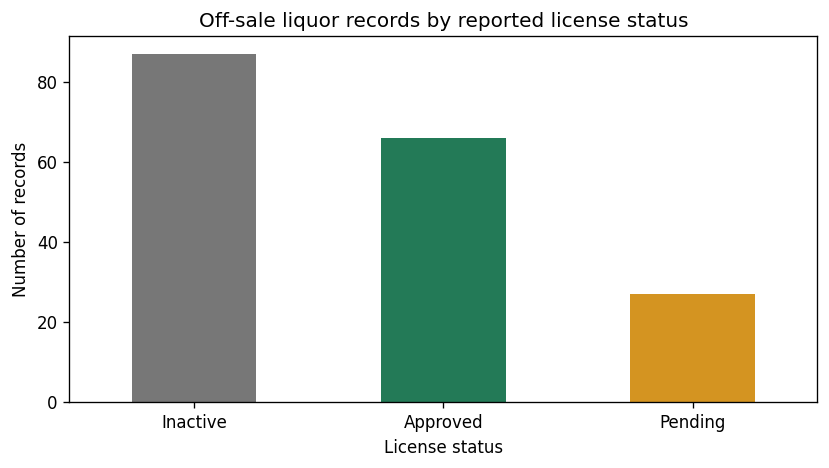

In [3]:
print("License status (all records):")
status_counts = df["licenseStatus"].value_counts(dropna=False)
print(status_counts.to_string())
print("\nLicense type by status (all records):")
print(pd.crosstab(df["licenseType"], df["licenseStatus"]).to_string())
print("\nMost frequent neighborhood labels (all records, including inactive):")
print(df["neighborhood"].fillna("Missing neighborhood").value_counts().head(10).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
status_counts.plot.bar(ax=ax, color=["#777777", "#237a57", "#d49421"], rot=0)
ax.set(title="Off-sale liquor records by reported license status", xlabel="License status", ylabel="Number of records")
fig.tight_layout()
fig.savefig(FIGURES / "license_status.png", dpi=160)
plt.show()


## Repeated license numbers

Compare repeated IDs before deciding whether and how to deduplicate. Different licenses can
also share an address or business name. These are different counting units. Neither the
raw row count nor the distinct-license count is automatically a store count.


In [4]:
repeated = df.loc[df["licenseNumber"].duplicated(keep=False)].sort_values(["licenseNumber", "OBJECTID"])
print(f"Rows beyond the first per license number: {df['licenseNumber'].duplicated().sum()}")
print(f"License numbers appearing more than once: {repeated['licenseNumber'].nunique()}")
print("\nExample repeated license records:")
print(repeated[["OBJECTID", "licenseNumber", "licenseName", "licenseStatus", "endorsements"]].head(14).to_string(index=False))
approved = df.loc[df["licenseStatus"].eq("Approved")]
print(f"\nApproved: {len(approved)} records, {approved['licenseNumber'].nunique()} distinct license numbers.")
print("'Approved' is the source label; it does not independently verify that a business is currently operating.")


Rows beyond the first per license number: 22
License numbers appearing more than once: 21

Example repeated license records:
 OBJECTID licenseNumber                     licenseName licenseStatus                    endorsements
      105     LIC107149                      56 Brewing      Approved                             NaN
      106     LIC107149                      56 Brewing      Approved                             NaN
      172     LIC107867          Fulton Brewing Company       Pending                             NaN
      173     LIC107867          Fulton Brewing Company       Pending                             NaN
      119     LIC337786          Indeed Brewing Company      Approved                             NaN
      120     LIC337786          Indeed Brewing Company      Approved                             NaN
      139     LIC337803           Surly Brewing Company       Pending                             NaN
      140     LIC337803           Surly Brewing Company    

## Coordinate checks and a first location plot

Points at `(0, 0)` are outside Minneapolis. Keep them in tabular summaries but exclude them
from this location plot. Also screen missing coordinates and coordinates outside a broad
Minneapolis-area bounding box (longitude −93.4 to −93.1; latitude 44.85 to 45.1).
This box is a sanity check, not a city boundary or an independent location verification.

Use the returned point geometry for the plot. Compare it with the rounded latitude/longitude
attributes to detect inconsistencies. Overlapping records can appear as one point; this plot
shows locations, not a density estimate. There is no basemap or city boundary.


Zero-coordinate records: 7
Records plotted: 173; records excluded: 7
 OBJECTID        licenseName              address licenseStatus  longitude  latitude
       13    Top Ten Liquors       1440 5TH ST SE      Approved        0.0       0.0
       92       Trader Joe's 721 WASHINGTON AVE S       Pending        0.0       0.0
      117           Eastlake   920 LAKE ST E #123      Inactive        0.0       0.0
      118           Eastlake   920 LAKE ST E #123      Inactive        0.0       0.0
      131  Finnegans Brew Co        817 5TH AVE S      Inactive        0.0       0.0
      132  Finnegans Brew Co        817 5TH AVE S      Inactive        0.0       0.0
      151 MGM Wine & Spirits  3058 EXCELSIOR BLVD      Approved        0.0       0.0

Maximum difference between geometry and coordinate attributes (degrees):
longitude    0.000014
latitude     0.000016


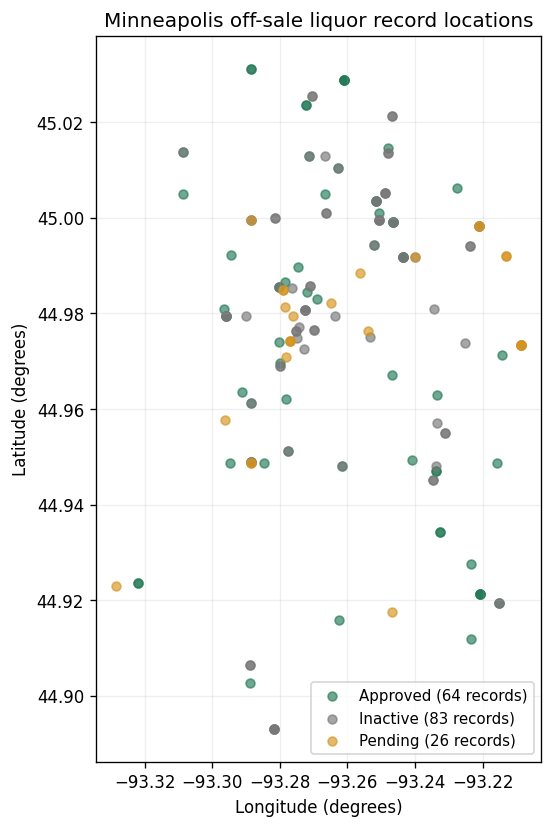

In [5]:
geometry = pd.DataFrame([feature.get("geometry") or {} for feature in payload["features"]], index=df.index)
assert payload["spatialReference"]["wkid"] == 4326
coordinate_check = pd.DataFrame({
    "OBJECTID": df["OBJECTID"],
    "licenseName": df["licenseName"],
    "address": df["address"],
    "licenseStatus": df["licenseStatus"],
    "longitude": geometry["x"],
    "latitude": geometry["y"],
})
zero_coordinates = geometry["x"].eq(0) & geometry["y"].eq(0)
map_ok = geometry["x"].between(-93.4, -93.1) & geometry["y"].between(44.85, 45.1)
print(f"Zero-coordinate records: {zero_coordinates.sum()}")
print(f"Records plotted: {map_ok.sum()}; records excluded: {(~map_ok).sum()}")
print(coordinate_check.loc[~map_ok].to_string(index=False))
print("\nMaximum difference between geometry and coordinate attributes (degrees):")
print(pd.Series({"longitude": (geometry["x"] - df["long"]).abs().max(),
                 "latitude": (geometry["y"] - df["lat"]).abs().max()}).to_string())

colors = {"Approved": "#237a57", "Inactive": "#777777", "Pending": "#d49421"}
fig, ax = plt.subplots(figsize=(7, 7))
for status, color in colors.items():
    selected = map_ok & df["licenseStatus"].eq(status)
    ax.scatter(geometry.loc[selected, "x"], geometry.loc[selected, "y"],
               label=f"{status} ({selected.sum()} records)", color=color, alpha=0.65, s=28)
# Correct the display aspect approximately for this latitude; do not measure distances here.
import math
ax.set_aspect(1 / math.cos(math.radians(45)))
ax.set(title="Minneapolis off-sale liquor record locations", xlabel="Longitude (degrees)", ylabel="Latitude (degrees)")
ax.legend(fontsize=9)
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES / "license_locations.png", dpi=160)
plt.show()


## Initial observations and possible next steps

- The snapshot has **180 records, 19 attribute columns, 158 distinct license numbers**, and
  **103 distinct address strings**. These are different counting units.
- Reported statuses are **87 Inactive, 66 Approved, and 27 Pending**. Approved records
  contain **53 distinct license numbers**. An analysis of currently approved licenses should
  explicitly filter status and investigate repeated IDs.
- **7 records have zero coordinates**, **10 lack ward and neighborhood labels**, and
  **124 lack endorsements**. A blank endorsement is not evidence that a license has none.
- The snapshot includes historical inactive records. Issue dates range from 2015 to 2026,
  but annual issue counts would not by themselves measure openings or licensing trends.

Possible next questions: How do reported statuses vary by license type? How are distinct
Approved license numbers distributed across neighborhood labels? The latter requires deciding
how to handle repeated license numbers and missing labels. Comparing access or concentration
per resident would additionally require population data; these records contain no sales,
consumption, population, or health outcome measures.

The source metadata says the dataset is refreshed on the last Friday of each month; downloaded
exports can lag portal updates. These are observations from the saved snapshot, not a live inventory.
These checks support exploration; they do not replace the independently established expectation
and student inspection required for Task 7.3.


## Basic summaries: counting units and repeated attributes

All summaries labeled **records** retain the 180 source rows. Distinct-license counts use
`licenseNumber`. Neither unit is a count of businesses. Check whether repeated license
numbers differ on any attribute before considering deduplication.


In [6]:
status_summary = pd.DataFrame({
    "records": df.groupby("licenseStatus").size(),
    "distinct_license_numbers": df.groupby("licenseStatus")["licenseNumber"].nunique(),
})
status_summary["percent_of_records"] = (100 * status_summary["records"] / len(df)).round(1)
print("Status summary (percentages use all 180 source records):")
print(status_summary.to_string())

# Ignore only the source row ID when comparing attributes.
attribute_columns = df.columns.drop("OBJECTID")
exact_repeat_count = df.duplicated(subset=attribute_columns).sum()
license_variation = df.groupby("licenseNumber")[attribute_columns.drop("licenseNumber")].nunique(dropna=False)
conflicting_ids = license_variation.index[license_variation.gt(1).any(axis=1)]
print(f"\nRows repeating every attribute except OBJECTID: {exact_repeat_count}")
print(f"License numbers with conflicting attribute values: {len(conflicting_ids)}")
print("Example repeated ID, retaining source row identifiers:")
print(df.loc[df["licenseNumber"].eq("LIC107149"),
             ["OBJECTID", "licenseNumber", "licenseName", "licenseStatus", "address"]].to_string(index=False))
print("\nDistinct license numbers are useful for a license-level analysis; addresses may still hold multiple licenses.")

missing_summary = df.isna().sum().rename("missing_records").to_frame()
missing_summary["percent_of_records"] = (100 * missing_summary["missing_records"] / len(df)).round(1)
print("\nFields with missing values (zero coordinates are flagged separately):")
print(missing_summary.loc[missing_summary["missing_records"].gt(0)].sort_values("missing_records", ascending=False).to_string())


Status summary (percentages use all 180 source records):
               records  distinct_license_numbers  percent_of_records
licenseStatus                                                       
Approved            66                        53                36.7
Inactive            87                        86                48.3
Pending             27                        19                15.0

Rows repeating every attribute except OBJECTID: 22
License numbers with conflicting attribute values: 0
Example repeated ID, retaining source row identifiers:
 OBJECTID licenseNumber licenseName licenseStatus           address
      105     LIC107149  56 Brewing      Approved 3055 COLUMBIA AVE
      106     LIC107149  56 Brewing      Approved 3055 COLUMBIA AVE

Distinct license numbers are useful for a license-level analysis; addresses may still hold multiple licenses.

Fields with missing values (zero coordinates are flagged separately):
              missing_records  percent_of_records
en

## License types and statuses

The type codes below are the source values, rather than assumed definitions. The chart
counts all source rows, including repeated license numbers. Compare the adjacent
license-level table to see how repeats affect the type totals. Status is an administrative
label; the dataset does not establish whether a business is open or why a license is inactive.


Record counts by type and status:
licenseStatus  Approved  Inactive  Pending
licenseType                               
BLBrewery            24        44       12
BLDistill             5        17        0
BLLiqOff             37        26       15

Percent within each license type (records):
licenseStatus  Approved  Inactive  Pending
licenseType                               
BLBrewery          30.0      55.0     15.0
BLDistill          22.7      77.3      0.0
BLLiqOff           47.4      33.3     19.2

Distinct license numbers by type and status:
licenseStatus  Approved  Inactive  Pending
licenseType                               
BLBrewery            13        44        6
BLDistill             3        17        0
BLLiqOff             37        25       13


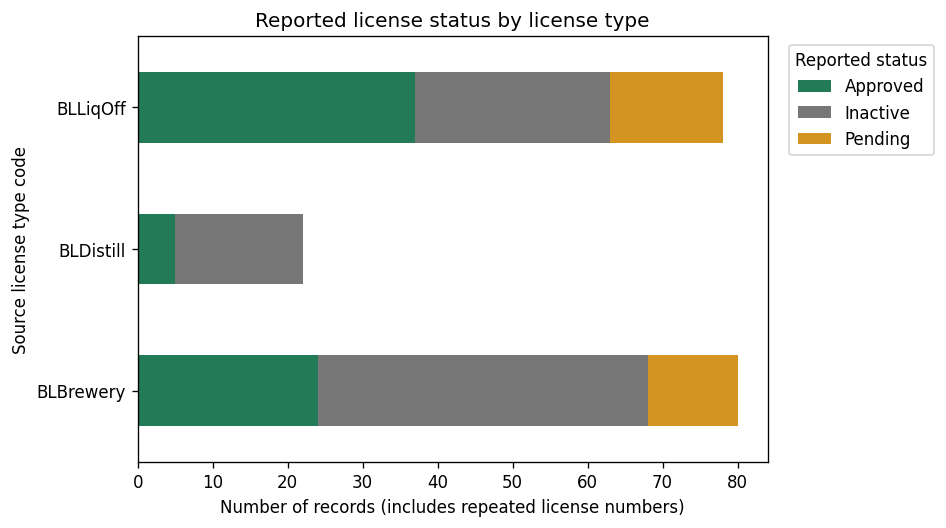

In [7]:
type_status = pd.crosstab(df["licenseType"], df["licenseStatus"]).reindex(
    columns=["Approved", "Inactive", "Pending"], fill_value=0)
print("Record counts by type and status:")
print(type_status.to_string())
print("\nPercent within each license type (records):")
print(type_status.div(type_status.sum(axis=1), axis=0).mul(100).round(1).to_string())
print("\nDistinct license numbers by type and status:")
print(df.groupby(["licenseType", "licenseStatus"])["licenseNumber"].nunique().unstack(fill_value=0).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
type_status.plot.barh(stacked=True, ax=ax, color=["#237a57", "#777777", "#d49421"])
ax.set(title="Reported license status by license type", xlabel="Number of records (includes repeated license numbers)", ylabel="Source license type code")
ax.legend(title="Reported status", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "license_type_status.png", dpi=160, bbox_inches="tight")
plt.show()


## Neighborhood labels

These counts combine Approved, Inactive, and Pending records. They describe where records
are assigned, not current store availability. Missing labels remain in the table; the chart
shows only the ten most frequent named neighborhoods. A missing neighborhood label does not
necessarily imply missing coordinates. Counts have no population or area adjustment.


Neighborhood labels with the most records (all statuses):
                                 records  distinct_license_numbers
neighborhood_label                                                
Downtown West                         17                        14
North Loop                            13                        11
Logan Park                            12                        11
Missing neighborhood                  10                         9
Lowry Hill East                        9                         8
Mid - City Industrial                  9                         7
Beltrami                               7                         6
Prospect Park - East River Road        7                         5
Harrison                               6                         5
Ericsson                               5                         3
Hawthorne                              5                         5
Holland                                5                         5

Rec

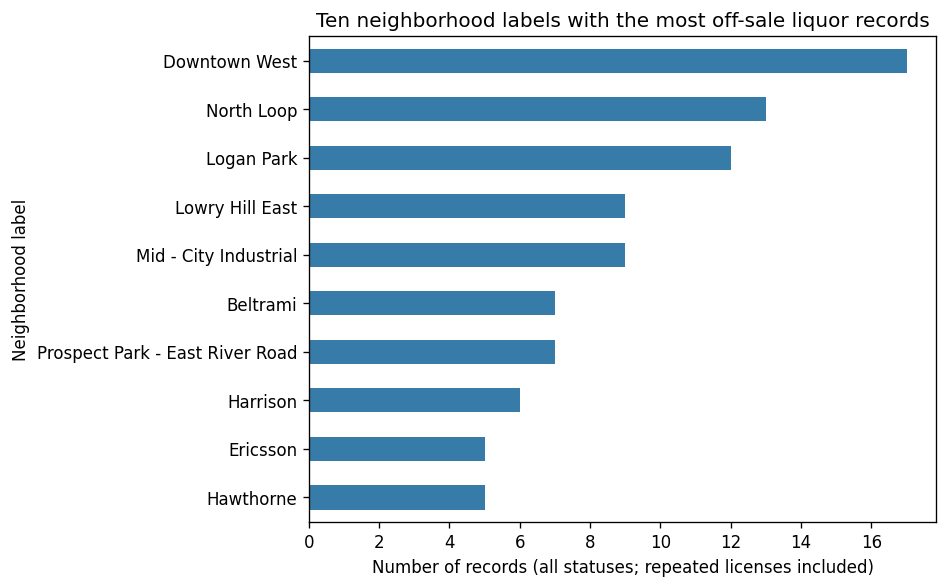

In [8]:
neighborhood_summary = (
    df.assign(neighborhood_label=df["neighborhood"].fillna("Missing neighborhood"))
      .groupby("neighborhood_label")
      .agg(records=("OBJECTID", "size"), distinct_license_numbers=("licenseNumber", "nunique"))
      .sort_values(["records", "neighborhood_label"], ascending=[False, True])
)
print("Neighborhood labels with the most records (all statuses):")
print(neighborhood_summary.head(12).to_string())
print(f"\nRecords without neighborhood labels: {df['neighborhood'].isna().sum()}")

# Alphabetical tie-breaking makes the top-ten selection reproducible.
named_top_ten = neighborhood_summary.drop(index="Missing neighborhood", errors="ignore").head(10)
fig, ax = plt.subplots(figsize=(8, 5))
named_top_ten["records"].iloc[::-1].plot.barh(ax=ax, color="#377ba8")
ax.set(title="Ten neighborhood labels with the most off-sale liquor records", xlabel="Number of records (all statuses; repeated licenses included)", ylabel="Neighborhood label")
fig.tight_layout()
fig.savefig(FIGURES / "neighborhood_records.png", dpi=160, bbox_inches="tight")
plt.show()


## Surprising patterns from the basic exploration

- **Duplicate attributes affect status counts unevenly.** All 22 rows beyond the first
  per license repeat every attribute except `OBJECTID`. The status counts are
  66 Approved / 87 Inactive / 27 Pending records, versus 53 / 86 / 19 distinct license
  numbers. No repeated license number has conflicting attribute values in this snapshot.
  This supports a license-level summary using distinct IDs; the source does not explain
  why the repeats were created.
- **Almost half the records are Inactive:** 87/180 = 48.3%. This is not a current-store
  inventory and cannot establish a closure rate.
- **Status varies by type.** Of the source records, 17/22 `BLDistill` records (77.3%) are
  Inactive, compared with 26/78 `BLLiqOff` records (33.3%). The data do not explain this
  difference, and repeated IDs affect these percentages.
- **Neighborhood rankings depend on the counting unit.** Downtown West has 17 records
  but 14 distinct license numbers; North Loop has 13 records but 11 distinct license
  numbers. All statuses are included.
- **Coordinates can be present but unusable.** Seven records have `(0, 0)`, including
  Approved records for Top Ten Liquors and MGM Wine & Spirits. These seven records
  stay in tables and are excluded from the location plot.
- **Missing endorsements dominate the missing-value table:** 124/180 = 68.9%. The source
  does not explain whether blank means not applicable, not recorded, or no endorsement.

A manageable next analysis would compare distinct Approved license numbers across neighborhood
labels, retaining an explicit missing-neighborhood category. Counts alone would not measure
access per resident or explain differences between neighborhoods.


## Mapping licenses with Minneapolis neighborhood boundaries

The gray polygons are the [City of Minneapolis neighborhood boundary layer](https://www.arcgis.com/home/item.html?id=ea0561bb00a94ba8b286a736464ee326),
downloaded November 11, 2026. The boundary snapshot has 87 polygons. Some boundary names
may differ from the license records' neighborhood labels. Here the polygons provide
geographic context; **no neighborhood-name join is used**.

Locations come from the license point geometry requested in EPSG:4326 (longitude first,
latitude second). `OBJECTID`, `licenseNumber`, and `apn` are identifiers, not coordinates.
Both boundary and point coordinates are converted to Web Mercator (EPSG:3857) for display.
This projection is suitable for this overview; do not use the map to measure ground distances.

The map uses **one point per distinct license number** after confirming that repeated license
numbers have identical attributes apart from `OBJECTID`. Shared locations can still overlap.
Zero coordinates, missing geometry, and points outside a broad Minneapolis-area bounding box
are excluded and written to a review CSV. The bounding box is a sanity screen, not a city boundary test.


In [9]:
boundaries = json.loads((DATA / "minneapolis_neighborhoods.geojson").read_text())
boundary_count = json.loads((DATA / "minneapolis_neighborhoods_count.json").read_text())["count"]
assert boundaries["type"] == "FeatureCollection"
assert len(boundaries["features"]) == boundary_count, "Incomplete neighborhood download."
assert not boundaries.get("exceededTransferLimit", False)
assert boundaries["crs"]["properties"]["name"] in {"urn:ogc:def:crs:OGC:1.3:CRS84", "EPSG:4326", "urn:ogc:def:crs:EPSG::4326"}

# Verify the choice to take the first row per license; retain that row's point geometry.
attribute_columns = df.columns.drop(["OBJECTID", "licenseNumber"])
variation = df.groupby("licenseNumber")[attribute_columns].nunique(dropna=False)
assert not variation.gt(1).any().any(), "Repeated license numbers have conflicting attributes."
license_points = df.assign(
    longitude=geometry["x"], latitude=geometry["y"]
).drop_duplicates("licenseNumber").copy()
license_points["map_ok"] = (
    license_points["longitude"].between(-93.4, -93.1)
    & license_points["latitude"].between(44.85, 45.1)
)
excluded = license_points.loc[~license_points["map_ok"], [
    "OBJECTID", "licenseNumber", "licenseName", "address", "licenseStatus", "longitude", "latitude"
]].copy()
excluded["reason"] = "Missing geometry or outside broad Minneapolis-area bounds"
zero = excluded["longitude"].eq(0) & excluded["latitude"].eq(0)
excluded.loc[zero, "reason"] = "Zero coordinates (0, 0)"
excluded.to_csv(ROOT / "analysis" / "unmapped_licenses.csv", index=False)

print(f"Neighborhood polygons: {len(boundaries['features'])}")
print(f"Source rows: {len(df)}; distinct license numbers: {len(license_points)}")
print(f"Plotted distinct licenses: {license_points['map_ok'].sum()}; excluded: {len(excluded)}")
print("\nMap accounting by reported status:")
map_accounting = license_points.groupby("licenseStatus").agg(
    distinct_licenses=("licenseNumber", "size"), mapped=("map_ok", "sum")
)
map_accounting["excluded"] = map_accounting["distinct_licenses"] - map_accounting["mapped"]
print(map_accounting.to_string())
print("\nExcluded licenses (also saved to analysis/unmapped_licenses.csv):")
print(excluded.to_string(index=False))


Neighborhood polygons: 87
Source rows: 180; distinct license numbers: 158
Plotted distinct licenses: 151; excluded: 7

Map accounting by reported status:
               distinct_licenses  mapped  excluded
licenseStatus                                     
Approved                      53      51         2
Inactive                      86      82         4
Pending                       19      18         1

Excluded licenses (also saved to analysis/unmapped_licenses.csv):
 OBJECTID licenseNumber        licenseName              address licenseStatus  longitude  latitude                  reason
       13     LIC393157    Top Ten Liquors       1440 5TH ST SE      Approved        0.0       0.0 Zero coordinates (0, 0)
       92      LIC54114       Trader Joe's 721 WASHINGTON AVE S       Pending        0.0       0.0 Zero coordinates (0, 0)
      117     LIC107382           Eastlake   920 LAKE ST E #123      Inactive        0.0       0.0 Zero coordinates (0, 0)
      118     LIC352403         

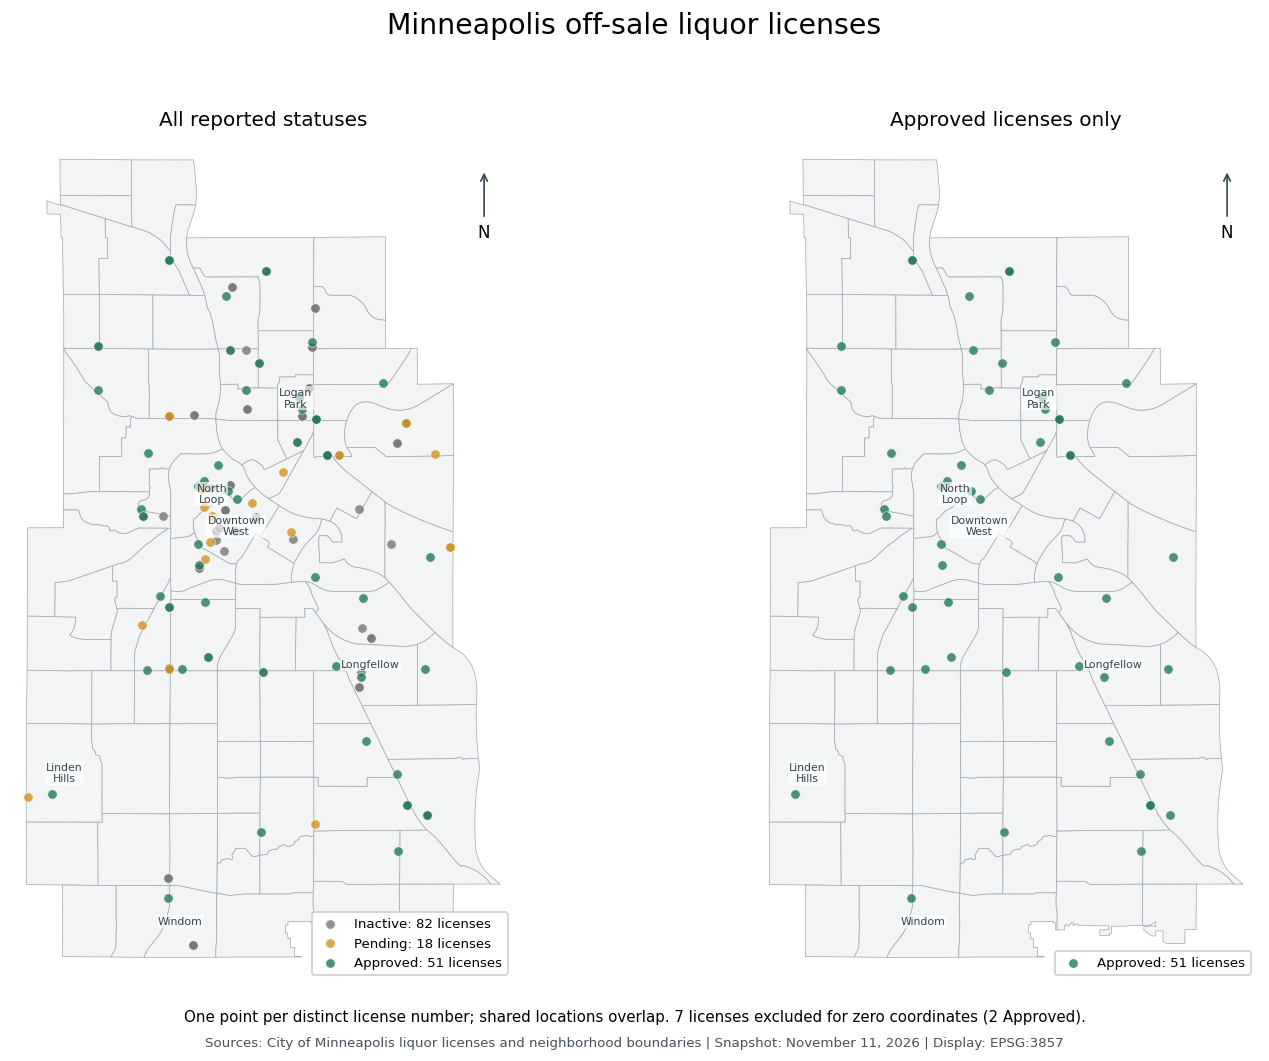

In [10]:
import math
from matplotlib.path import Path as PlotPath
from matplotlib.patches import PathPatch

EARTH_RADIUS = 6378137.0

def web_mercator(longitude, latitude):
    """Convert longitude/latitude degrees to EPSG:3857 display coordinates."""
    x = EARTH_RADIUS * math.radians(longitude)
    y = EARTH_RADIUS * math.log(math.tan(math.pi / 4 + math.radians(latitude) / 2))
    return x, y

# Render all rings together so polygon holes remain part of the boundary shape.
# GeoJSON supplies ring order/orientation. Both Polygon and MultiPolygon are supported.
boundary_paths = []
label_positions = {}
for feature in boundaries["features"]:
    shape = feature["geometry"]
    assert shape["type"] in {"Polygon", "MultiPolygon"}
    polygons = [shape["coordinates"]] if shape["type"] == "Polygon" else shape["coordinates"]
    for rings in polygons:
        vertices, codes = [], []
        for ring in rings:
            projected = [web_mercator(lon, lat) for lon, lat, *rest in ring]
            vertices.extend(projected)
            codes.extend([PlotPath.MOVETO] + [PlotPath.LINETO] * (len(projected) - 2) + [PlotPath.CLOSEPOLY])
        boundary_paths.append(PlotPath(vertices, codes))
    name = feature["properties"].get("BDNAME")
    if name in {"Downtown West", "North Loop", "Logan Park", "Longfellow", "Linden Hills", "Windom"}:
        outer = polygons[0][0]
        lon = (min(v[0] for v in outer) + max(v[0] for v in outer)) / 2
        lat = (min(v[1] for v in outer) + max(v[1] for v in outer)) / 2
        label_positions[name] = web_mercator(lon, lat)

mapped_licenses = license_points.loc[license_points["map_ok"]].copy()
projected_points = [web_mercator(lon, lat) for lon, lat in zip(mapped_licenses["longitude"], mapped_licenses["latitude"])]
mapped_licenses["map_x"] = [point[0] for point in projected_points]
mapped_licenses["map_y"] = [point[1] for point in projected_points]
status_colors = {"Approved": "#237a57", "Inactive": "#777777", "Pending": "#d49421"}
fig, axes = plt.subplots(1, 2, figsize=(13, 9))
for ax, approved_only in zip(axes, [False, True]):
    for boundary_path in boundary_paths:
        ax.add_patch(PathPatch(boundary_path, facecolor="#f3f4f5", edgecolor="#a5acb2", linewidth=0.45, zorder=0))
    subset = mapped_licenses.loc[mapped_licenses["licenseStatus"].eq("Approved")] if approved_only else mapped_licenses
    for status in ["Inactive", "Pending", "Approved"]:
        selected = subset.loc[subset["licenseStatus"].eq(status)]
        if selected.empty:
            continue
        ax.scatter(selected["map_x"], selected["map_y"], s=32, alpha=0.8,
                   color=status_colors[status], edgecolors="white", linewidths=0.4,
                   label=f"{status}: {len(selected)} licenses", zorder=2)
    # The same boundary extent is used for both panels.
    ax.autoscale_view()
    ax.margins(0.03)
    ax.set_aspect("equal")
    for name, position in label_positions.items():
        ax.annotate(name.replace(" ", "\n", 1), position, fontsize=6.5, color="#344451", ha="center", va="center",
                    bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.65, "pad":0.8}, zorder=3)
    ax.annotate("N", xy=(0.94, 0.96), xytext=(0.94, 0.88), xycoords="axes fraction", ha="center",
                arrowprops={"arrowstyle":"->", "color":"#344451"}, fontsize=10)
    ax.set_title("Approved licenses only" if approved_only else "All reported statuses", fontsize=12)
    ax.legend(loc="lower right", fontsize=8, framealpha=0.95)
    ax.set_axis_off()
fig.suptitle("Minneapolis off-sale liquor licenses", fontsize=17, y=0.98)
fig.text(0.5, 0.045, "One point per distinct license number; shared locations overlap. 7 licenses excluded for zero coordinates (2 Approved).", ha="center", fontsize=9)
fig.text(0.5, 0.022, "Sources: City of Minneapolis liquor licenses and neighborhood boundaries | Snapshot: November 11, 2026 | Display: EPSG:3857", ha="center", fontsize=8, color="#45515b")
fig.tight_layout(rect=[0, 0.065, 1, 0.95])
fig.savefig(FIGURES / "liquor_license_map.png", dpi=180, bbox_inches="tight")
plt.show()


### What this map shows and what to verify

The map displays **151 of 158 distinct license numbers**, including **51 of 53 Approved
licenses**. It provides geographic context for reported licenses, not a count of distinct
stores or a measure of access per resident. Seven licenses remain in the saved data and
are listed in `analysis/unmapped_licenses.csv` for location review.

For Task 7.3, a useful independent check would be to locate two or three named businesses
using an authoritative address or parcel reference and compare those locations with the
plotted points. Record specific source identifiers, addresses, expected locations, and
any discrepancies. Agreement between two fields from this same dataset alone would not
independently establish that the locations are correct.
